In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split

iris = load_iris()

X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target
target_names = iris.target_names

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

In [2]:
rf_model = RandomForestClassifier(n_estimators=100, max_depth=3, random_state=42)
rf_model.fit(X_train, y_train)

y_train_pred = rf_model.predict(X_train)
y_test_pred = rf_model.predict(X_test)

In [3]:
def print_metrics(y_train, y_pred, dataset_name):
    acc = accuracy_score(y_train, y_pred)
    prec = precision_score(y_train, y_pred, average='macro')
    rec = recall_score(y_train, y_pred, average='macro')
    f1 = f1_score(y_train, y_pred, average='macro')
    
    print(f"--- {dataset_name} ---")
    print(f"Accuracy (Правильные ответы):       {acc:.4f}")
    print(f"Precision (Точность):               {prec:.4f}")
    print(f"Recall (Полнота):                   {rec:.4f}")
    print(f"F1-score (Баланс точности/полноты): {f1:.4f}\n")

print_metrics(y_train, y_train_pred, "ОБУЧАЮЩАЯ ВЫБОРКА (Train)")
print_metrics(y_test, y_test_pred, "ТЕСТОВАЯ ВЫБОРКА (Test)")

print("Отчет по каждому сорту на тестовой выборке:")
print(classification_report(y_test, y_test_pred, target_names=target_names))

--- ОБУЧАЮЩАЯ ВЫБОРКА (Train) ---
Accuracy (Правильные ответы):       0.9714
Precision (Точность):               0.9717
Recall (Полнота):                   0.9714
F1-score (Баланс точности/полноты): 0.9714

--- ТЕСТОВАЯ ВЫБОРКА (Test) ---
Accuracy (Правильные ответы):       0.9111
Precision (Точность):               0.9155
Recall (Полнота):                   0.9111
F1-score (Баланс точности/полноты): 0.9107

Отчет по каждому сорту на тестовой выборке:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.82      0.93      0.88        15
   virginica       0.92      0.80      0.86        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45



In [4]:
new_flower = pd.DataFrame([[5.1, 3.5, 1.4, 0.2]], columns=iris.feature_names)
predicted_class_index = rf_model.predict(new_flower)[0]
predicted_species = target_names[predicted_class_index]

print(f"Предсказанный сорт для нового образца: {predicted_species}\n")

Предсказанный сорт для нового образца: setosa



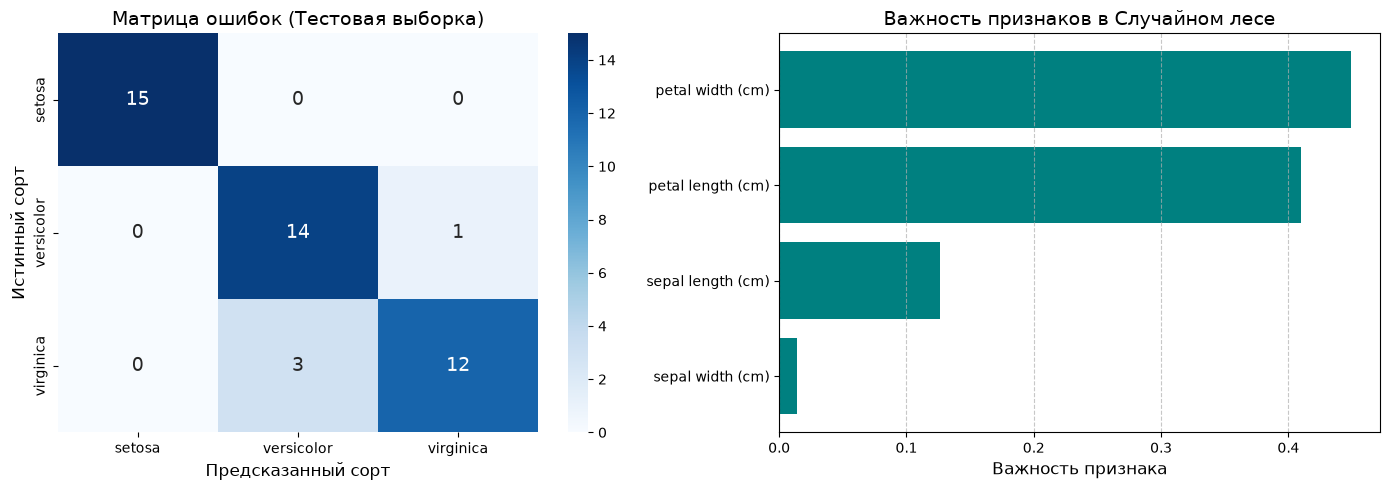

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues', 
    xticklabels=target_names, yticklabels=target_names,
    annot_kws={"size": 14}, ax=axes[0]
)
axes[0].set_title('Матрица ошибок (Тестовая выборка)', fontsize=14)
axes[0].set_xlabel('Предсказанный сорт', fontsize=12)
axes[0].set_ylabel('Истинный сорт', fontsize=12)

importances = rf_model.feature_importances_
feature_imp_df = pd.DataFrame({
    'Признак': iris.feature_names,
    'Важность': importances
}).sort_values(by='Важность', ascending=True)

axes[1].barh(feature_imp_df['Признак'], feature_imp_df['Важность'], color='teal')
axes[1].set_title('Важность признаков в Случайном лесе', fontsize=14)
axes[1].set_xlabel('Важность признака', fontsize=12)
axes[1].grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()